# Spotify Hierarchical Clustering with Union-Find (Kruskal-style)
Pipeline: preprocessing -> kNN edge graph -> Union-Find Kruskal merging -> cluster evaluation and visualisation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             normalized_mutual_info_score, pairwise_distances_argmin)
from scipy.cluster.hierarchy import linkage, dendrogram

RAW_FILE = 'spotify-tracks-dataset-detailed.csv'
SEED = 0

## 1. Load data

In [2]:
data = pd.read_csv(RAW_FILE, low_memory=False)
print('Raw shape:', data.shape)
display(data.head())
data.info()

Raw shape: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  str    
 1   artists           113999 non-null  str    
 2   album_name        113999 non-null  str    
 3   track_name        113999 non-null  str    
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           114000 non-nu

## 2. Feature selection

In [3]:
# Sound-based features used for scaling and distance calculations
features = ['danceability', 'energy', 'acousticness', 'instrumentalness', 'liveness',
            'speechiness', 'valence', 'tempo', 'loudness']
bounded_features = ['danceability', 'energy', 'acousticness', 'instrumentalness',
                    'liveness', 'speechiness', 'valence']
# popularity is listener metadata, not a sound characteristic -> kept in metadata only
print('Selected audio features:', features)

Selected audio features: ['danceability', 'energy', 'acousticness', 'instrumentalness', 'liveness', 'speechiness', 'valence', 'tempo', 'loudness']


## 3. Cleaning: exact duplicates, missing values, invalid values

In [4]:
rows_raw = len(data)
data = data.drop_duplicates().copy()
print('Exact duplicate rows removed:', rows_raw - len(data))

data = data.dropna(subset=['track_id', 'track_name', 'artists'])
data[features] = data[features].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=features + ['popularity', 'track_genre']).copy()

# [0, 1] features must be in range; tempo <= 0 / time_signature <= 0 / duration <= 0 are failed analyses
valid = data[bounded_features].ge(0).all(axis=1) & data[bounded_features].le(1).all(axis=1)
valid &= (data['tempo'] > 0) & (data['time_signature'] > 0) & (data['duration_ms'] > 0)
print('Rows removed for invalid values:', (~valid).sum())
data = data.loc[valid].copy()

for col in ['popularity', 'duration_ms', 'key', 'mode', 'time_signature']:
    data[col] = data[col].astype(int)
print('Shape after cleaning:', data.shape)

Exact duplicate rows removed: 450
Rows removed for invalid values: 163
Shape after cleaning: (113386, 20)


## 4. Song-level duplicates
The same song appears under several genres (same `track_id`) and re-releases share identical audio features. Those rows sit at distance 0 and would create trivial merges, so each song is kept once. Every genre a track was listed under is kept in `all_genres`.

In [5]:
print('Repeated track_ids:', data['track_id'].duplicated().sum())
print('Rows with identical audio features:', data.duplicated(subset=features).sum())

all_genres = (data.groupby('track_id')['track_genre']
                  .agg(lambda s: '|'.join(sorted(set(s)))).rename('all_genres'))
data = data.drop_duplicates(subset='track_id', keep='first').merge(all_genres, on='track_id', how='left')
data = data.drop_duplicates(subset=features, keep='first').reset_index(drop=True)

assert not data['track_id'].duplicated().any()
assert not data.duplicated(subset=features).any()
print('Final cleaned shape:', data.shape, '| genres:', data['track_genre'].nunique())

Repeated track_ids: 23808
Rows with identical audio features: 30049
Final cleaned shape: (83337, 21) | genres: 113


## 5. Correlation check

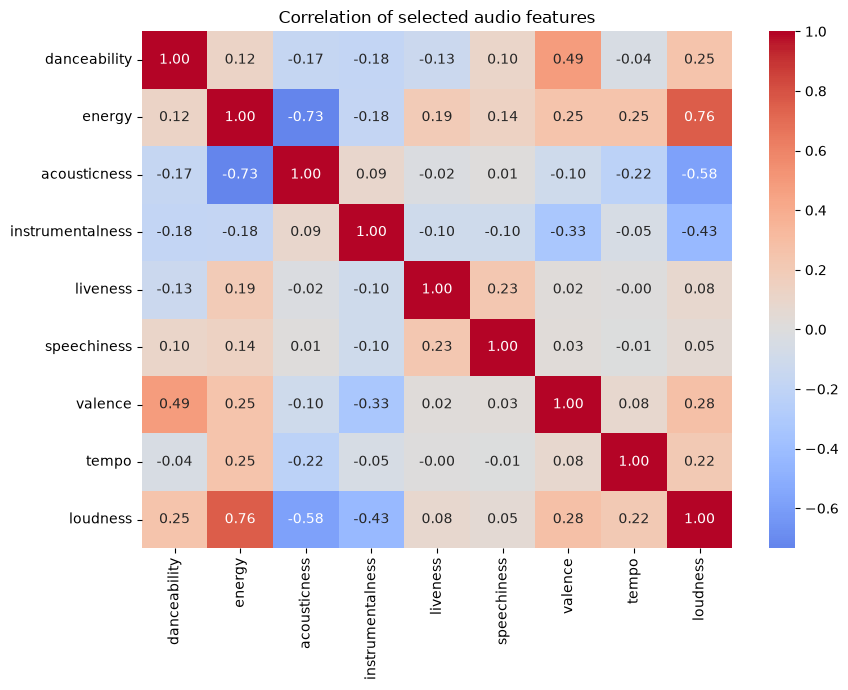

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(data[features].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of selected audio features'); plt.tight_layout(); plt.show()

## 6. Scaling

,mean,std,min,max
danceability,0.0,1.0,-2.901,2.415
energy,0.0,1.0,-2.475,1.413
acousticness,0.0,1.0,-0.968,1.967
instrumentalness,-0.0,1.0,-0.550,2.493
liveness,0.0,1.0,-1.064,3.964
speechiness,0.0,1.0,-0.575,7.573
valence,0.0,1.0,-1.774,2.012
tempo,0.0,1.0,-3.108,4.078
loudness,-0.0,1.0,-7.280,2.502


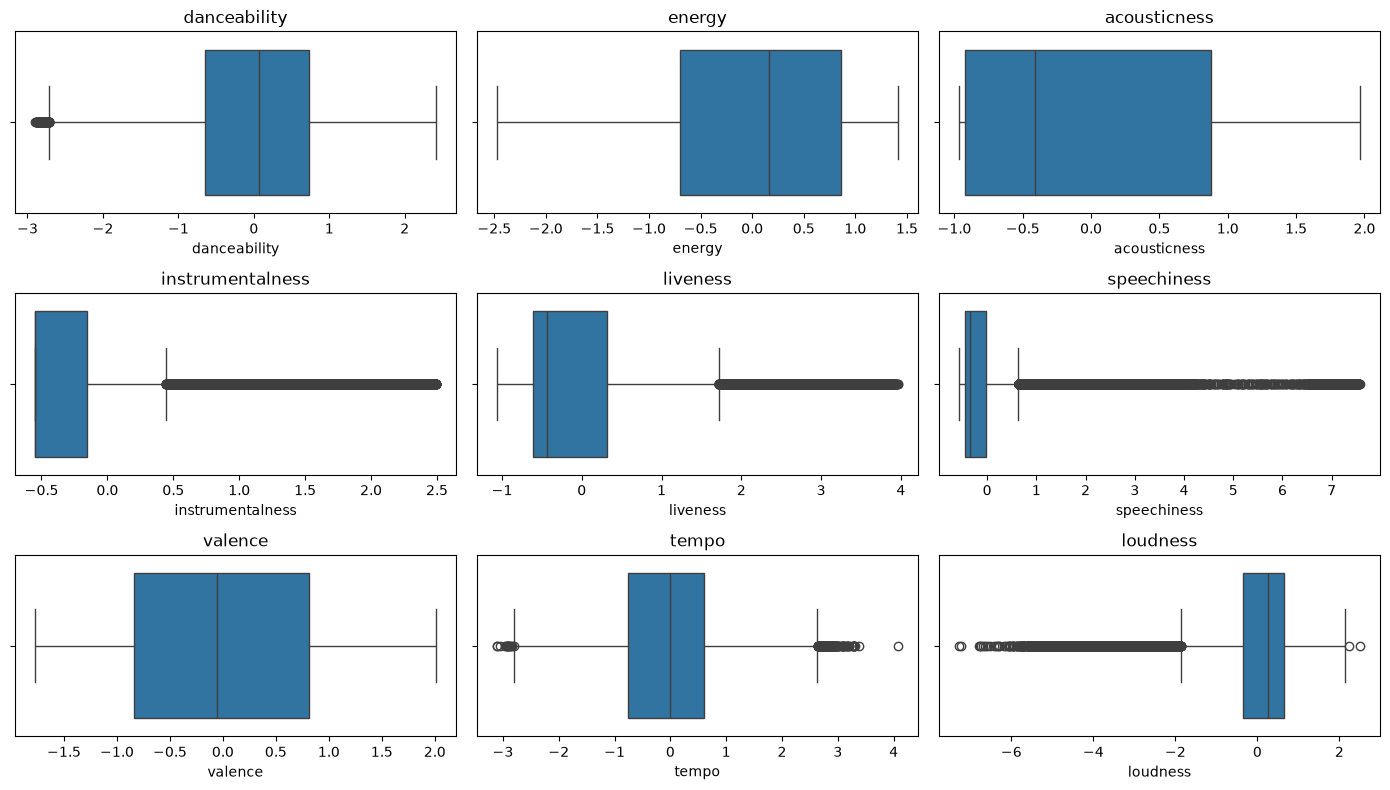

In [7]:
scaler = StandardScaler()
scaled_features = pd.DataFrame(scaler.fit_transform(data[features]), columns=features)
X = scaled_features.to_numpy(dtype=np.float32)
n = len(X)

assert len(data) == n
assert np.isfinite(X).all(), 'NaN/inf in scaled data'
display(scaled_features.describe().T[['mean', 'std', 'min', 'max']].round(3))

fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for ax, f in zip(axes.ravel(), features):
    sns.boxplot(x=scaled_features[f], ax=ax); ax.set_title(f)
plt.tight_layout(); plt.show()

## 7. Save preprocessing outputs (row-aligned)

In [8]:
metadata_columns = ['track_id', 'track_name', 'artists', 'track_genre', 'all_genres', 'popularity']
data.to_csv('spotify_cleaned.csv', index=False)
scaled_features.to_csv('spotify_scaled_features.csv', index=False)
data[metadata_columns].to_csv('spotify_metadata.csv', index=False)

print('PREPROCESSING SUMMARY')
print('Songs:', n, '| features:', len(features))
print('Duplicate track_ids:', int(data['track_id'].duplicated().sum()))
print('Duplicate feature vectors:', int(data.duplicated(subset=features).sum()))
print('Non-positive tempo:', int((data['tempo'] <= 0).sum()))

PREPROCESSING SUMMARY
Songs: 83337 | features: 9
Duplicate track_ids: 0
Duplicate feature vectors: 0
Non-positive tempo: 0


## 8. Union-Find (Disjoint Set) from scratch
Path halving in `find` and union by size.

In [9]:
class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
        self.size = [1] * n
        self.components = n

    def find(self, x):
        # Return the root of x, halving the path as it goes
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        # Merge the sets of a and b; False if they were already merged
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.size[ra] < self.size[rb]:
            ra, rb = rb, ra
        self.parent[rb] = ra
        self.size[ra] += self.size[rb]
        self.components -= 1
        return True

    def connected(self, a, b):
        return self.find(a) == self.find(b)

    def component_size(self, x):
        return self.size[self.find(x)]


# Sanity checks
t = UnionFind(6)
assert t.union(0, 1) and t.union(1, 2) and not t.union(0, 2)
assert t.connected(0, 2) and not t.connected(0, 4)
assert t.component_size(1) == 3 and t.components == 4
t.union(3, 4); t.union(4, 5); t.union(2, 3)
assert t.component_size(5) == 6 and t.components == 1
print('Union-Find tests passed.')

Union-Find tests passed.


## 9. Candidate edges: symmetric k-nearest-neighbour graph
All ~2 billion pairs cannot be stored, so each song keeps its k nearest neighbours. An edge is kept if **either** song lists the other (no neighbour link is lost), repeated pairs are removed, and edges longer than `THRESHOLD` are dropped.

The neighbours are computed once for `K_MAX = 30`; smaller `K` just uses the first `K` columns (used in the sensitivity analysis in section 14).

In [10]:
K_MAX = 30
nn = NearestNeighbors(n_neighbors=K_MAX + 1, metric='euclidean', n_jobs=-1).fit(X)
dist_all, idx_all = nn.kneighbors(X)       # column 0 is the song itself

def build_edges(K, threshold):
    src = np.repeat(np.arange(n), K)
    dst = idx_all[:, 1:K + 1].ravel()
    w = dist_all[:, 1:K + 1].ravel()
    keep = src != dst
    if threshold is not None:
        keep &= (w <= threshold)
    e = pd.DataFrame({'track_i_index': np.minimum(src[keep], dst[keep]),
                      'track_j_index': np.maximum(src[keep], dst[keep]),
                      'euclidean_distance': w[keep]})
    return (e.drop_duplicates(['track_i_index', 'track_j_index'])
             .sort_values('euclidean_distance', kind='stable').reset_index(drop=True))

K = 20
THRESHOLD = 2.0
edges = build_edges(K, THRESHOLD)
edges.to_csv('spotify_all_euclidean_distances.csv', index=False)

eu = edges['track_i_index'].tolist()
ev = edges['track_j_index'].tolist()

has_edge = np.zeros(n, bool); has_edge[edges['track_i_index']] = True; has_edge[edges['track_j_index']] = True
print(f'Edges: {len(edges):,} | songs with no edge within {THRESHOLD}: {(~has_edge).sum()}')
print('Edge distance quantiles:', edges['euclidean_distance'].quantile([.5, .9, .99]).round(3).to_dict())

Edges: 1,138,212 | songs with no edge within 2.0: 38
Edge distance quantiles: {0.5: 0.715, 0.9: 1.144, 0.99: 1.667}


## 10. Kruskal merging with a size cap, and a stated rule for choosing `M`
Edges are added in increasing distance (as when building an MST). An edge is skipped only when **both** groups already hold at least `M` songs, which stops big clusters from fusing into one giant cluster.

**Rule for `M`:** try a grid of values and keep the one with the **best silhouette score, subject to the largest cluster holding under 40% of the songs**. The number of clusters is therefore not given in advance; it follows from `M`. Groups of `SMALL` songs or fewer are attached to the nearest larger cluster by centroid distance.

,M,clusters,largest_cluster_%,silhouette
0,20,201,3.761,-0.154
1,30,94,7.870,-0.126
2,45,54,13.343,-0.084
3,68,27,16.552,-0.031
4,101,14,19.119,0.034
5,152,10,24.677,0.068
6,228,7,34.898,0.080
7,342,5,59.575,0.176
8,513,5,59.575,0.176
9,769,4,78.952,0.184


Chosen M = 228


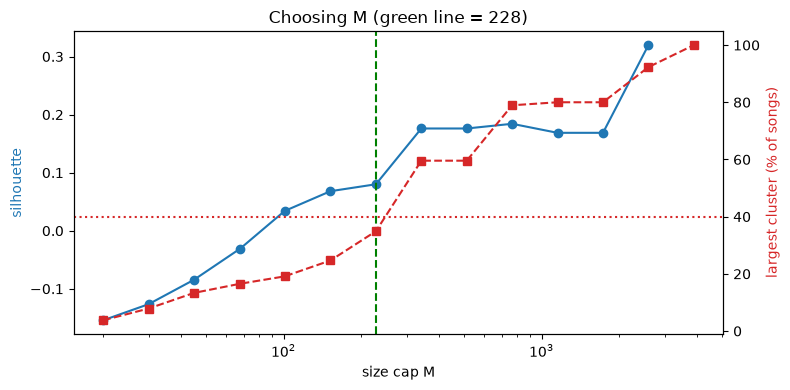

In [11]:
MAX_SHARE = 0.40            # largest cluster must hold less than this share of the songs
SIL_SAMPLE = 10000          # silhouette is computed on a fixed random sample for speed
SMALL = 10
M_GRID = [int(round(20 * 1.5 ** i)) for i in range(14)]

def kruskal_capped(M, eu, ev):
    uf = UnionFind(n)
    find, size = uf.find, uf.size
    for a, b in zip(eu, ev):
        ra, rb = find(a), find(b)
        if ra != rb and (size[ra] < M or size[rb] < M):
            uf.union(ra, rb)
    return uf

def finalize(uf):
    # Final labels; groups of SMALL songs or fewer join the nearest larger cluster
    labels = np.unique([uf.find(i) for i in range(n)], return_inverse=True)[1]
    sizes = np.bincount(labels)
    small, big = np.where(sizes <= SMALL)[0], np.where(sizes > SMALL)[0]
    if len(small) and len(big):
        centres = pd.DataFrame(X).groupby(labels).mean().to_numpy()
        remap = np.arange(len(sizes))
        remap[small] = big[pairwise_distances_argmin(centres[small], centres[big])]
        labels = np.unique(remap[labels], return_inverse=True)[1]
    return labels, len(small), int(sizes[small].sum())

def select_M(eu, ev, keep_runs=False):
    rows, runs = [], {}
    for m in M_GRID:
        uf = kruskal_capped(m, eu, ev)
        lab, _, _ = finalize(uf)
        k = int(lab.max()) + 1
        rows.append({'M': m, 'clusters': k,
                     'largest_cluster_%': 100 * np.bincount(lab).max() / n,
                     'silhouette': silhouette_score(X, lab, sample_size=SIL_SAMPLE, random_state=SEED) if k > 1 else np.nan})
        if keep_runs:
            runs[m] = uf
    table = pd.DataFrame(rows)
    ok = table[(table['clusters'] > 1) & (table['largest_cluster_%'] < 100 * MAX_SHARE)]
    if len(ok):
        chosen = int(ok.loc[ok['silhouette'].idxmax(), 'M'])
    else:                                   # nothing satisfies the limit: take the most balanced result
        chosen = int(table.loc[table['largest_cluster_%'].idxmin(), 'M'])
    return table, chosen, runs

M_table, M, runs = select_M(eu, ev, keep_runs=True)
display(M_table.round(3))
print(f'Chosen M = {M}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(M_table['M'], M_table['silhouette'], 'o-', c='tab:blue')
ax.set_xscale('log'); ax.set_xlabel('size cap M'); ax.set_ylabel('silhouette', color='tab:blue')
ax2 = ax.twinx()
ax2.plot(M_table['M'], M_table['largest_cluster_%'], 's--', c='tab:red')
ax2.axhline(100 * MAX_SHARE, c='tab:red', ls=':'); ax2.set_ylabel('largest cluster (% of songs)', color='tab:red')
ax.axvline(M, c='g', ls='--'); ax.set_title(f'Choosing M (green line = {M})')
plt.tight_layout(); plt.show()

## 11. Final clusters

In [12]:
uf = runs[M]
labels, n_tiny, tiny_songs = finalize(uf)
print(f'Tiny groups attached to a larger cluster: {n_tiny} ({tiny_songs} songs)')

data['cluster'] = labels
sizes = np.bincount(labels)
print(f'Clusters: {len(sizes)} | sizes: {sorted(sizes.tolist(), reverse=True)}')

def report(name, lab):
    print(f'{name:<22} k={len(set(lab)):<3} silhouette={silhouette_score(X, lab, sample_size=SIL_SAMPLE, random_state=SEED):.3f}  '
          f'Davies-Bouldin={davies_bouldin_score(X, lab):.3f}  NMI vs genre={normalized_mutual_info_score(data["track_genre"], lab):.3f}')

report('Union-Find (Kruskal)', labels)
report('K-Means (reference)', KMeans(len(sizes), n_init=3, random_state=SEED).fit_predict(X))

Tiny groups attached to a larger cluster: 43 (51 songs)
Clusters: 7 | sizes: [29083, 20566, 14344, 10248, 6399, 1809, 888]
Union-Find (Kruskal)   k=7   silhouette=0.080  Davies-Bouldin=2.151  NMI vs genre=0.147
K-Means (reference)    k=7   silhouette=0.197  Davies-Bouldin=1.387  NMI vs genre=0.178


## 12. Merge history

In [13]:
hist_uf = UnionFind(n)
node_id = np.arange(n)          # id of the current cluster node at each root (n, n+1, ... for merged nodes)
rows = []
for a, b, d in zip(eu, ev, edges['euclidean_distance'].to_numpy()):
    ra, rb = hist_uf.find(a), hist_uf.find(b)
    if ra != rb and not (hist_uf.size[ra] >= M and hist_uf.size[rb] >= M):
        left, right = node_id[ra], node_id[rb]
        new_size = hist_uf.size[ra] + hist_uf.size[rb]
        hist_uf.union(a, b)
        node_id[hist_uf.find(a)] = n + len(rows)
        rows.append([left, right, float(d), new_size])

merge_history = pd.DataFrame(rows, columns=['Cluster A', 'Cluster B', 'Distance', 'New Size'])
merge_history.to_csv('spotify_merge_history.csv', index=False)
print('Recorded merges:', len(merge_history), '| zero-distance merges:', int((merge_history['Distance'] == 0).sum()))
assert merge_history['Distance'].is_monotonic_increasing
display(merge_history.head())
display(merge_history.tail())

Recorded merges: 83287 | zero-distance merges: 0


,Cluster A,Cluster B,Distance,New Size
0,2782,2880,0.000015,2
1,25983,63929,0.000015,2
2,25635,25872,0.000034,2
3,52746,52905,0.000034,2
4,42222,53509,0.000034,2


,Cluster A,Cluster B,Distance,New Size
83282,166616,76605,1.976642,29083
83283,166618,47021,1.980520,6378
83284,166588,43999,1.983259,869
83285,76255,166620,1.995807,6379
83286,166621,16382,1.998965,870


## 13. Visualisation

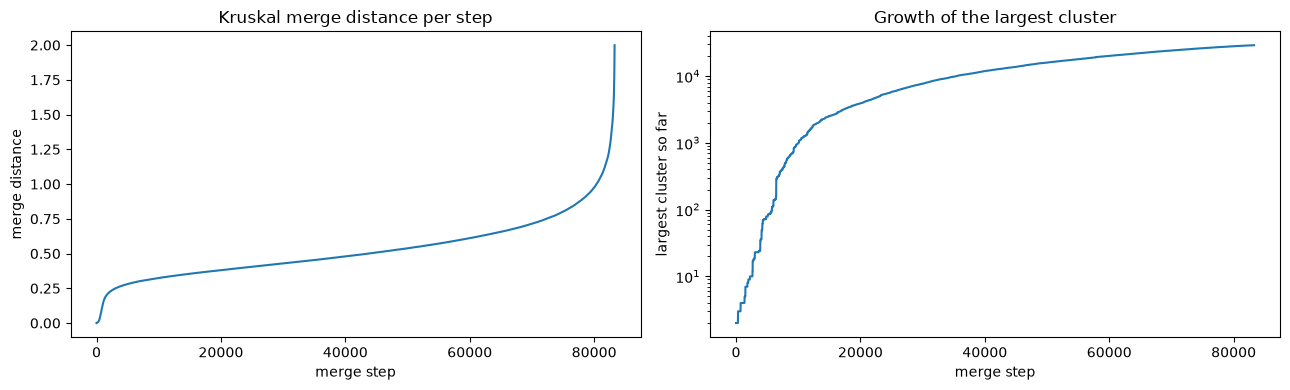

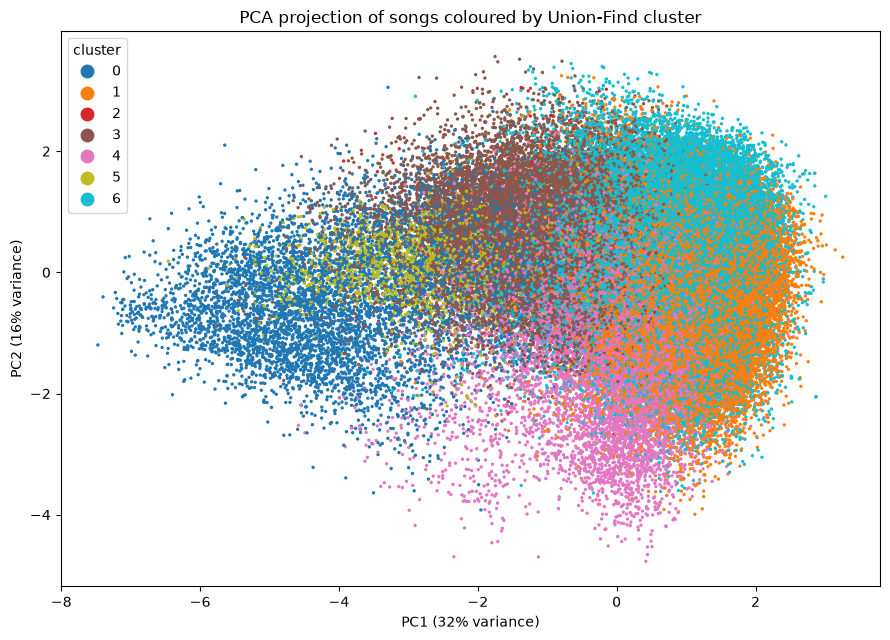

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(merge_history['Distance'].to_numpy())
ax[0].set_xlabel('merge step'); ax[0].set_ylabel('merge distance'); ax[0].set_title('Kruskal merge distance per step')
ax[1].plot(merge_history['New Size'].cummax().to_numpy())
ax[1].set_yscale('log'); ax[1].set_xlabel('merge step'); ax[1].set_ylabel('largest cluster so far'); ax[1].set_title('Growth of the largest cluster')
plt.tight_layout(); plt.show()

pca = PCA(2, random_state=SEED)
Z = pca.fit_transform(X)
plt.figure(figsize=(9, 6.5))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=labels, s=2, cmap='tab10')
plt.legend(*sc.legend_elements(), title='cluster', markerscale=1.5, loc='best')
plt.xlabel(f'PC1 ({100*pca.explained_variance_ratio_[0]:.0f}% variance)')
plt.ylabel(f'PC2 ({100*pca.explained_variance_ratio_[1]:.0f}% variance)')
plt.title('PCA projection of songs coloured by Union-Find cluster')
plt.tight_layout(); plt.show()

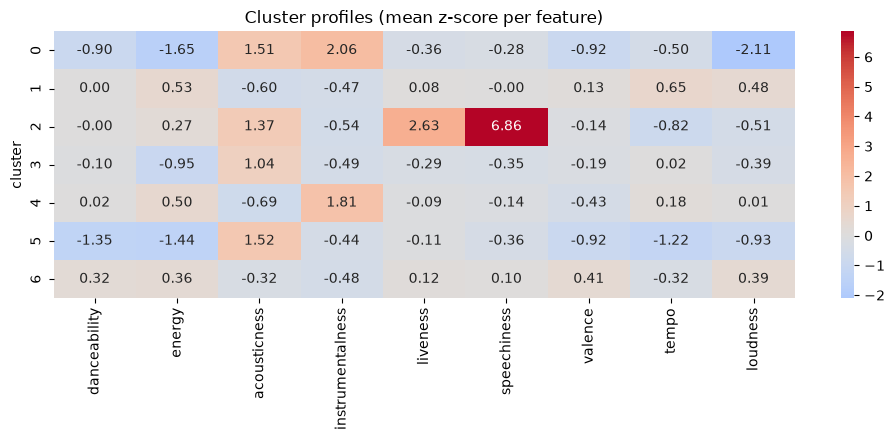

,size,top genres
cluster,,
0,6399,"new-age (11%), ambient (10%), study (9%)"
1,20566,"j-idol (3%), hardstyle (2%), happy (2%)"
2,888,"comedy (90%), kids (1%), show-tunes (1%)"
3,14344,"honky-tonk (5%), cantopop (5%), tango (4%)"
4,10248,"detroit-techno (7%), minimal-techno (7%), grin..."
5,1809,"opera (16%), romance (12%), show-tunes (8%)"
6,29083,"salsa (2%), dancehall (2%), kids (2%)"


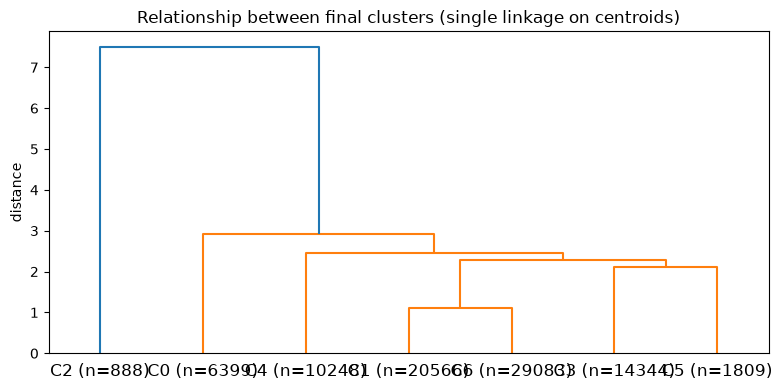

In [15]:
# Cluster profiles: mean of each (scaled) feature per cluster
profile = scaled_features.groupby(labels).mean()
profile.index.name = 'cluster'
plt.figure(figsize=(10, 4.5))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster profiles (mean z-score per feature)'); plt.tight_layout(); plt.show()

summary = data.groupby('cluster').agg(size=('track_id', 'size'))
summary['top genres'] = data.groupby('cluster')['track_genre'].agg(
    lambda s: ', '.join(f'{g} ({v*100:.0f}%)' for g, v in s.value_counts(normalize=True).head(3).items()))
display(summary)

# Dendrogram of how the final clusters relate (single linkage on cluster centroids)
cent = profile.to_numpy()
plt.figure(figsize=(8, 4))
dendrogram(linkage(cent, method='single'), labels=[f'C{c} (n={s})' for c, s in zip(profile.index, sizes)])
plt.title('Relationship between final clusters (single linkage on centroids)')
plt.ylabel('distance'); plt.tight_layout(); plt.show()

## 14. Sensitivity of the choices
The same pipeline (including the `M` rule) is re-run with different neighbour counts `K` and distance thresholds. A threshold of `none` keeps every kNN edge. Stable cluster counts and scores mean the result does not hinge on one lucky setting.

In [16]:
rows = []
for K_s in (10, 20, 30):
    for thr_s in (1.5, 2.0, None):
        e = build_edges(K_s, thr_s)
        eu_s, ev_s = e['track_i_index'].tolist(), e['track_j_index'].tolist()
        _, M_s, _ = select_M(eu_s, ev_s)
        lab_s, _, _ = finalize(kruskal_capped(M_s, eu_s, ev_s))
        linked = np.zeros(n, bool); linked[e['track_i_index']] = True; linked[e['track_j_index']] = True
        rows.append({'K': K_s, 'threshold': 'none' if thr_s is None else thr_s, 'edges': len(e),
                     'songs without edge': int((~linked).sum()), 'chosen M': M_s,
                     'clusters': int(lab_s.max()) + 1,
                     'largest cluster %': round(100 * np.bincount(lab_s).max() / n, 1),
                     'silhouette': round(silhouette_score(X, lab_s, sample_size=SIL_SAMPLE, random_state=SEED), 3),
                     'Davies-Bouldin': round(davies_bouldin_score(X, lab_s), 3),
                     'NMI vs genre': round(normalized_mutual_info_score(data['track_genre'], lab_s), 3)})
sensitivity = pd.DataFrame(rows)
sensitivity.to_csv('spotify_sensitivity.csv', index=False)
display(sensitivity)

,K,threshold,edges,songs without edge,chosen M,clusters,largest cluster %,silhouette,Davies-Bouldin,NMI vs genre
0,10,1.5,566936,263,228,7,34.8,0.081,2.151,0.147
1,10,2.0,574970,38,228,7,34.9,0.080,2.151,0.147
2,10,none,576921,0,228,7,34.9,0.079,2.151,0.147
3,20,1.5,1112768,263,228,7,34.8,0.081,2.151,0.147
4,20,2.0,1138212,38,228,7,34.9,0.080,2.151,0.147
5,20,none,1145214,0,228,7,34.9,0.079,2.151,0.147
6,30,1.5,1650017,263,228,7,34.8,0.081,2.151,0.147
7,30,2.0,1700266,38,228,7,34.9,0.080,2.151,0.147
8,30,none,1714664,0,228,7,34.9,0.079,2.151,0.147


In [17]:
data[['track_id', 'track_name', 'artists', 'track_genre', 'all_genres', 'cluster']].to_csv('spotify_clusters.csv', index=False)
print('Saved spotify_clusters.csv')

Saved spotify_clusters.csv
